In [1]:
!pip install timm albumentations grad-cam -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'   # must be set before CUDA is used

import re, json, random, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, classification_report

warnings.filterwarnings("ignore")

def seed_everything(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

seed_everything(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [3]:
INPUT_ROOT = "/kaggle/input"
print("Contents of /kaggle/input:", os.listdir(INPUT_ROOT))

xlsx_path, csv_path, img_dir = None, None, None
for r, dirs, files in os.walk(INPUT_ROOT):
    for f in files:
        if f.lower() == "data.xlsx" and xlsx_path is None:
            xlsx_path = os.path.join(r, f)
        if f.lower() == "full_df.csv" and csv_path is None:
            csv_path = os.path.join(r, f)
    for d in dirs:
        if d.lower() == "preprocessed_images" and img_dir is None:
            img_dir = os.path.join(r, d)

print("XLSX:", xlsx_path)
print("CSV :", csv_path)
print("IMGS:", img_dir)

if (xlsx_path is None and csv_path is None) or img_dir is None:
    raise FileNotFoundError("Dataset not found. Click 'Add Input' and add 'Ocular Disease Recognition'.")

print("Number of images in folder:", len(os.listdir(img_dir)))

Contents of /kaggle/input: ['datasets']
XLSX: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/ODIR-5K/ODIR-5K/data.xlsx
CSV : /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/full_df.csv
IMGS: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images
Number of images in folder: 6392


In [4]:
df = pd.read_excel(xlsx_path) if xlsx_path is not None else pd.read_csv(csv_path)
print("Patients in table:", len(df))

CLASSES = ['N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']
CLASS_NAMES = {
    'N': 'Normal', 'D': 'Diabetic Retinopathy', 'G': 'Glaucoma',
    'C': 'Cataract', 'A': 'AMD', 'H': 'Hypertensive Retinopathy',
    'M': 'Pathological Myopia', 'O': 'Other abnormalities'
}
NUM_CLASSES = len(CLASSES)

def eye_labels(kw):
    kw = str(kw).lower()
    y = dict.fromkeys(CLASSES, 0)
    if 'normal fundus' in kw:
        y['N'] = 1
        return y
    if re.search(r'diabetic|proliferative', kw):  y['D'] = 1
    if 'glaucoma' in kw:                          y['G'] = 1
    if 'cataract' in kw:                          y['C'] = 1
    if re.search(r'age-related macular|amd', kw): y['A'] = 1
    if 'hypertensive' in kw:                      y['H'] = 1
    if 'myopia' in kw:                            y['M'] = 1
    if sum(y.values()) == 0:                      y['O'] = 1
    return y

rows = []
for _, r in df.iterrows():
    for side in ['Left', 'Right']:
        kw = r[f'{side}-Diagnostic Keywords']
        if re.search(r'no fundus image|anterior segment', str(kw).lower()):
            continue
        row = {'patient_id': r['ID'], 'filename': r[f'{side}-Fundus'], 'keywords': kw}
        row.update(eye_labels(kw))
        rows.append(row)

eyes = pd.DataFrame(rows)
existing = set(os.listdir(img_dir))
eyes = eyes[eyes['filename'].isin(existing)].reset_index(drop=True)
eyes['path'] = eyes['filename'].apply(lambda x: os.path.join(img_dir, x))

print("Total eye images:", len(eyes))
eyes.head()

Patients in table: 3500
Total eye images: 6392


,patient_id,filename,keywords,N,D,G,C,A,H,M,O,path
0,0,0_left.jpg,cataract,0,0,0,1,0,0,0,0,/kaggle/input/datasets/andrewmvd/ocular-diseas...
1,0,0_right.jpg,normal fundus,1,0,0,0,0,0,0,0,/kaggle/input/datasets/andrewmvd/ocular-diseas...
2,1,1_left.jpg,normal fundus,1,0,0,0,0,0,0,0,/kaggle/input/datasets/andrewmvd/ocular-diseas...
3,1,1_right.jpg,normal fundus,1,0,0,0,0,0,0,0,/kaggle/input/datasets/andrewmvd/ocular-diseas...
4,2,2_right.jpg,moderate non proliferative retinopathy,0,1,0,0,0,0,0,0,/kaggle/input/datasets/andrewmvd/ocular-diseas...


N    2874
D    1722
O     639
G     313
C     301
A     279
M     253
H     192
dtype: int64

Images with more than one disease: 181


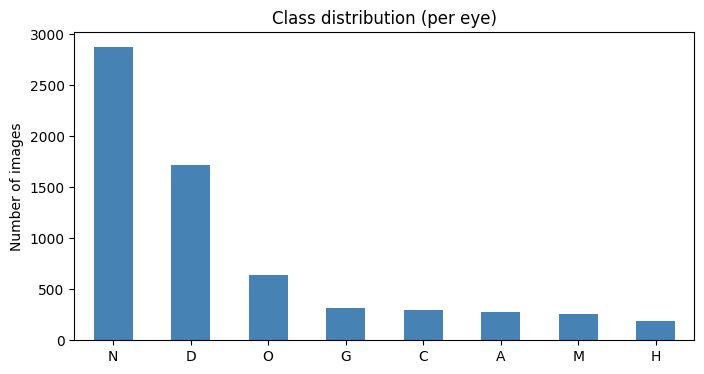

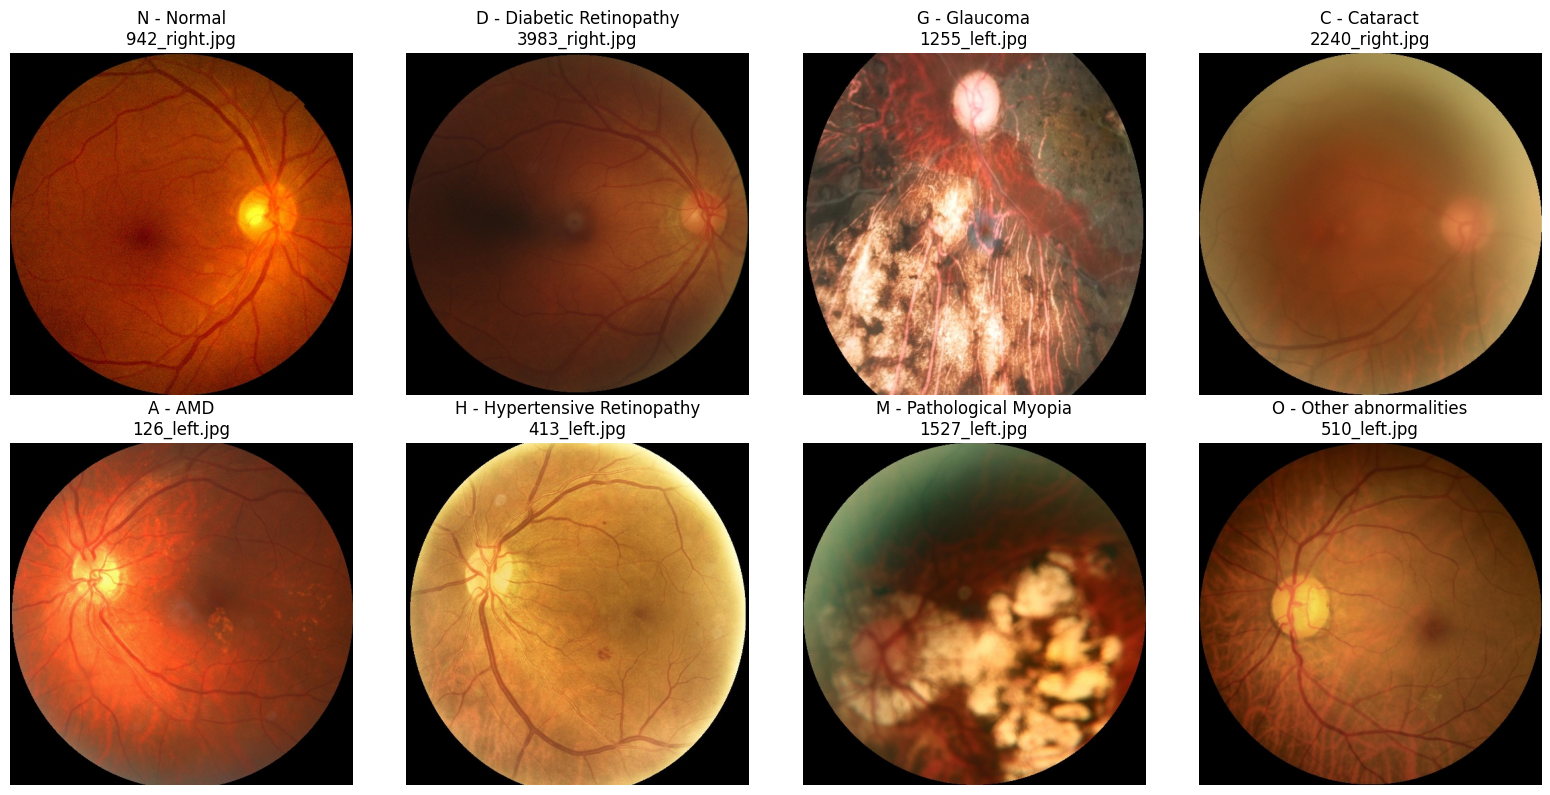

In [5]:
counts = eyes[CLASSES].sum().sort_values(ascending=False)
print(counts)
print("\nImages with more than one disease:", (eyes[CLASSES].sum(axis=1) > 1).sum())

plt.figure(figsize=(8, 4))
counts.plot(kind='bar', color='steelblue')
plt.title("Class distribution (per eye)")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, c in zip(axes.ravel(), CLASSES):
    s = eyes[eyes[c] == 1].sample(1, random_state=1).iloc[0]
    img = cv2.cvtColor(cv2.imread(s['path']), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f"{c} - {CLASS_NAMES[c]}\n{s['filename']}")
    ax.axis('off')
plt.tight_layout()
plt.show()

In [6]:
patients = eyes.groupby('patient_id')[CLASSES].max().reset_index()

train_p, temp_p = train_test_split(patients, test_size=0.30, random_state=42, stratify=patients['D'])
val_p, test_p   = train_test_split(temp_p,  test_size=0.50, random_state=42, stratify=temp_p['D'])

train_df = eyes[eyes['patient_id'].isin(train_p['patient_id'])].reset_index(drop=True)
val_df   = eyes[eyes['patient_id'].isin(val_p['patient_id'])].reset_index(drop=True)
test_df  = eyes[eyes['patient_id'].isin(test_p['patient_id'])].reset_index(drop=True)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(pd.DataFrame({'train': train_df[CLASSES].sum(),
                    'val':   val_df[CLASSES].sum(),
                    'test':  test_df[CLASSES].sum()}))

assert not set(train_df.patient_id) & set(val_df.patient_id)
assert not set(train_df.patient_id) & set(test_df.patient_id)
assert not set(val_df.patient_id) & set(test_df.patient_id)
print("\nNo patient leakage between splits ✔")

Train: 4475 | Val: 957 | Test: 960
   train  val  test
N   2014  423   437
D   1201  261   260
G    202   62    49
C    195   53    53
A    189   32    58
H    144   27    21
M    181   42    30
O    478   84    77

No patient leakage between splits ✔


caching:   0%|          | 0/4475 [00:00<?, ?it/s]

caching:   0%|          | 0/957 [00:00<?, ?it/s]

caching:   0%|          | 0/960 [00:00<?, ?it/s]

Cache size (GB): 2.83
Batch: torch.Size([16, 3, 384, 384]) torch.Size([16, 8])


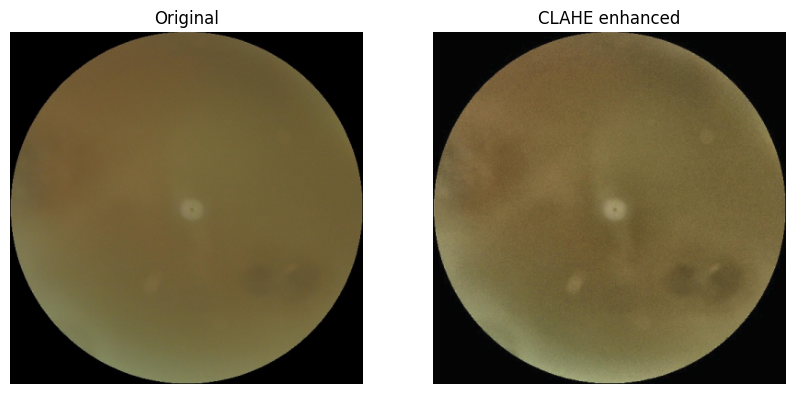

In [7]:
IMG_SIZE = 384
MEAN = (0.485, 0.456, 0.406)
STD  = (0.229, 0.224, 0.225)

def crop_black_borders(rgb, thr=10):
    """Crop the black background of a fundus photo and pad it to a square (for external images)."""
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    ys, xs = np.where(gray > thr)
    if len(ys) < 100:
        return rgb
    rgb = rgb[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = rgb.shape[:2]
    s = max(h, w)
    canvas = np.zeros((s, s, 3), dtype=rgb.dtype)
    canvas[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = rgb
    return canvas

def enhance(rgb):
    """CLAHE on the lightness channel: boosts vessels/lesions and keeps the colors."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    lab[..., 0] = clahe.apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def prepare_rgb(rgb, crop=False):
    if crop:
        rgb = crop_black_borders(rgb)
    return cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

def load_rgb(path, crop=False):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    return prepare_rgb(img, crop)

# ---- Cache all images (resized + CLAHE) in RAM once: makes training much faster ----
def build_cache(df):
    arr = np.zeros((len(df), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    for i, p in enumerate(tqdm(df['path'].values, desc="caching")):
        arr[i] = enhance(load_rgb(p))
    return arr

train_arr = build_cache(train_df)
val_arr   = build_cache(val_df)
test_arr  = build_cache(test_df)
print("Cache size (GB):", round((train_arr.nbytes + val_arr.nbytes + test_arr.nbytes) / 1e9, 2))

# ---- Augmentation (train only) ----
def make_compose(tfms):
    try:
        return A.Compose(tfms, seed=42)      # albumentations >= 2.0
    except TypeError:
        return A.Compose(tfms)               # older versions

train_tfms = make_compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-30, 30), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    A.RandomGamma(p=0.2),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])
eval_tfms = A.Compose([A.Normalize(mean=MEAN, std=STD), ToTensorV2()])

def to_tensor(rgb_resized):
    """Resized RGB -> normalized tensor [1,3,H,W] (same CLAHE + normalization as training)."""
    return eval_tfms(image=enhance(rgb_resized))['image'].unsqueeze(0)

class CachedDataset(Dataset):
    def __init__(self, arr, df, transform):
        self.arr = arr
        self.labels = df[CLASSES].values.astype(np.float32)
        self.transform = transform

    def __len__(self):
        return len(self.arr)

    def __getitem__(self, idx):
        img = self.transform(image=self.arr[idx])['image']
        return img, torch.from_numpy(self.labels[idx])

def worker_init_fn(_):
    """Deterministic but different seed per worker AND per epoch."""
    s = torch.initial_seed() % (2 ** 32)
    random.seed(s)
    np.random.seed(s)
    tf = torch.utils.data.get_worker_info().dataset.transform
    if hasattr(tf, 'set_random_seed'):
        try:
            tf.set_random_seed(s)
        except Exception:
            pass

BATCH_SIZE = 16   # use 8 if you get out-of-memory

def make_train_loader(seed):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(CachedDataset(train_arr, train_df, train_tfms), batch_size=BATCH_SIZE,
                      shuffle=True, generator=g, worker_init_fn=worker_init_fn,
                      num_workers=2, pin_memory=True, drop_last=True)

val_loader  = DataLoader(CachedDataset(val_arr, val_df, eval_tfms), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(CachedDataset(test_arr, test_df, eval_tfms), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=2, pin_memory=True)

imgs, labels = next(iter(make_train_loader(42)))
print("Batch:", imgs.shape, labels.shape)

s = train_df.iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(load_rgb(s['path'])); ax[0].set_title("Original"); ax[0].axis('off')
ax[1].imshow(train_arr[0]); ax[1].set_title("CLAHE enhanced"); ax[1].axis('off')
plt.show()

In [8]:
USE_AMP = True    # set False if NaN appears (slower but fully stable)
use_amp = USE_AMP and device.type == 'cuda'

def state_finite(m):
    """True if all weights and BatchNorm buffers are finite (no NaN/inf)."""
    return all(torch.isfinite(t).all().item()
               for t in list(m.parameters()) + list(m.buffers()) if t.is_floating_point())

def train_one_epoch(model, loader, criterion, optimizer, scaler, ema=None, clip=2.0):
    model.train()
    running_loss, n, skipped = 0.0, 0, 0
    for imgs, labels in tqdm(loader, leave=False, desc="train"):
        imgs = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=use_amp):
            logits = model(imgs)
        loss = criterion(logits.float(), labels)
        if not torch.isfinite(loss):
            skipped += 1
            continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        scaler.step(optimizer)
        scaler.update()
        if ema is not None:
            ema.update_parameters(model)
        running_loss += loss.item() * imgs.size(0)
        n += imgs.size(0)
    if skipped:
        print(f"  (skipped {skipped} non-finite batches)")
    return running_loss / max(n, 1)

@torch.no_grad()
def evaluate(model, loader, criterion):
    """Evaluation in fp32 (safer than fp16)."""
    model.eval()
    running_loss, n = 0.0, 0
    probs_all, labels_all = [], []
    for imgs, labels in tqdm(loader, leave=False, desc="eval"):
        imgs = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(imgs).float()
        running_loss += criterion(logits, labels).item() * imgs.size(0)
        n += imgs.size(0)
        probs_all.append(torch.sigmoid(logits).cpu().numpy())
        labels_all.append(labels.cpu().numpy())
    return running_loss / n, np.concatenate(probs_all), np.concatenate(labels_all)

@torch.no_grad()
def predict_tta(model, x):
    """Average sigmoid probabilities over 4 views: original, h-flip, v-flip, both flips."""
    views = [x, torch.flip(x, dims=[3]), torch.flip(x, dims=[2]), torch.flip(x, dims=[2, 3])]
    return torch.stack([torch.sigmoid(model(v).float()) for v in views]).mean(0)

def per_class_auc(y_true, y_prob):
    out = {}
    for i, c in enumerate(CLASSES):
        ok = 0 < y_true[:, i].sum() < len(y_true)
        out[c] = roc_auc_score(y_true[:, i], y_prob[:, i]) if ok else float('nan')
    return out

def find_best_thresholds(y_true, y_prob):
    th = {}
    for i, c in enumerate(CLASSES):
        best_t, best_f1 = 0.5, -1.0
        for t in np.arange(0.05, 0.951, 0.025):
            f1 = f1_score(y_true[:, i], (y_prob[:, i] >= t).astype(int), zero_division=0)
            if f1 > best_f1:
                best_t, best_f1 = t, f1
        th[c] = round(float(best_t), 3)
    return th

def make_pos_weight():
    pos = train_df[CLASSES].sum().values
    neg = len(train_df) - pos
    return torch.tensor(np.sqrt(neg / np.maximum(pos, 1)), dtype=torch.float32).to(device)

def fit(model, train_loader, val_loader, criterion, optimizer, scheduler, scaler,
        epochs, patience, save_path, ema):
    """Early stopping on val macro AUC (evaluating the EMA weights). Recovers from NaN automatically."""
    history = {'train_loss': [], 'val_loss': [], 'val_auc': []}
    best_auc, wait = 0.0, 0

    for epoch in range(1, epochs + 1):
        tr_loss = train_one_epoch(model, train_loader, criterion, optimizer, scaler, ema)

        if not (state_finite(model) and state_finite(ema.module)):
            print(f"Epoch {epoch:02d}: NaN in weights -> reloading best checkpoint")
            if os.path.exists(save_path):
                sd = torch.load(save_path, map_location=device)
                model.load_state_dict(sd)
                ema.module.load_state_dict(sd)
            scheduler.step()
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break
            continue

        va_loss, vp, vl = evaluate(ema, val_loader, criterion)
        scheduler.step()
        macro_auc = np.nanmean(list(per_class_auc(vl, vp).values()))
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['val_auc'].append(macro_auc)
        print(f"Epoch {epoch:02d}/{epochs} | train {tr_loss:.4f} | val {va_loss:.4f} | val_macro_AUC {macro_auc:.4f}")

        if macro_auc > best_auc:
            best_auc, wait = macro_auc, 0
            torch.save(ema.module.state_dict(), save_path)
            print(f"  -> saved best (AUC {best_auc:.4f})")
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break

    if history['val_auc']:
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))
        ax[0].plot(history['train_loss'], label='train'); ax[0].plot(history['val_loss'], label='val')
        ax[0].set_title('Loss'); ax[0].legend()
        ax[1].plot(history['val_auc'], color='green'); ax[1].set_title('Validation macro AUC')
        plt.show()
    return history, best_auc

print("Utilities ready. AMP:", use_amp)

Utilities ready. AMP: True



===== Training model with seed 42 =====


model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

train:   0%|          | 0/279 [00:00<?, ?it/s]

eval:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 01/20 | train 0.8142 | val 0.9094 | val_macro_AUC 0.5239
  -> saved best (AUC 0.5239)


... (50 outputs left out)

Epoch 18/20 | train 0.1500 | val 0.4609 | val_macro_AUC 0.8941


train:   0%|          | 0/279 [00:00<?, ?it/s]

eval:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 19/20 | train 0.1515 | val 0.4728 | val_macro_AUC 0.8937
Early stopping.


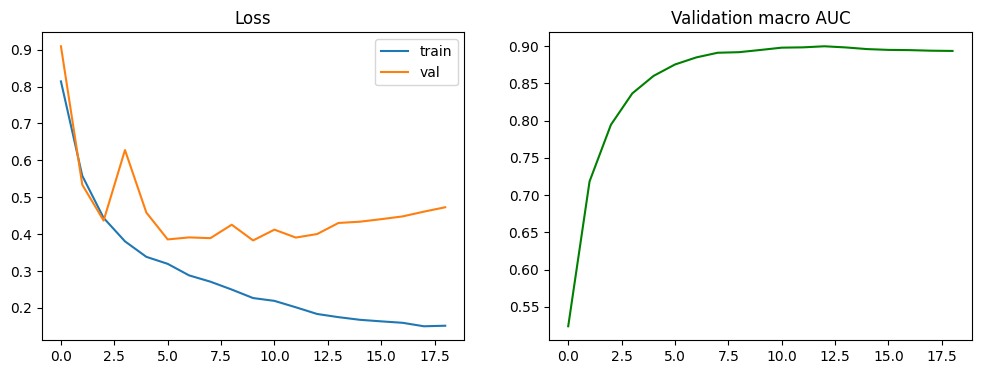

[seed 42] best val macro AUC: 0.9000

===== Training model with seed 123 =====


train:   0%|          | 0/279 [00:00<?, ?it/s]

eval:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 01/20 | train 0.8654 | val 0.7784 | val_macro_AUC 0.5544
  -> saved best (AUC 0.5544)


train:   0%|          | 0/279 [00:00<?, ?it/s]

eval:   0%|          | 0/60 [00:00<?, ?it/s]

... (42 outputs left out)

Epoch 16/20 | train 0.1601 | val 0.4633 | val_macro_AUC 0.8879


train:   0%|          | 0/279 [00:00<?, ?it/s]

eval:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 17/20 | train 0.1562 | val 0.4747 | val_macro_AUC 0.8871
Early stopping.


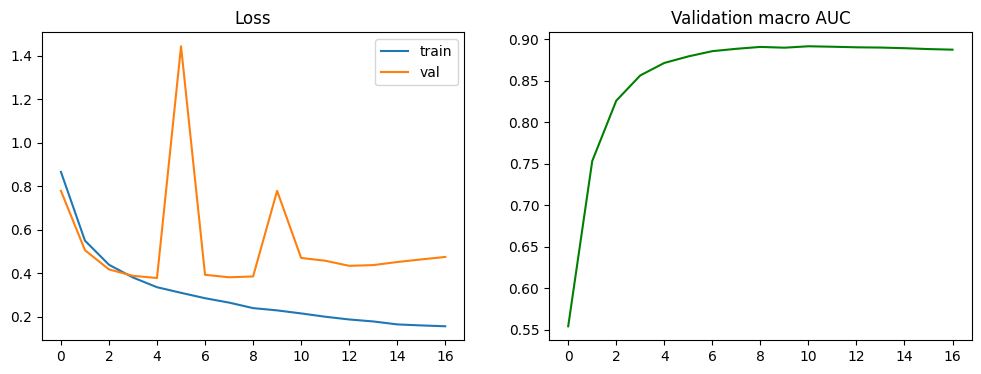

[seed 123] best val macro AUC: 0.8912

===== Training model with seed 2024 =====


train:   0%|          | 0/279 [00:00<?, ?it/s]

eval:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 01/20 | train 0.8677 | val 0.7954 | val_macro_AUC 0.5337
  -> saved best (AUC 0.5337)


train:   0%|          | 0/279 [00:00<?, ?it/s]

eval:   0%|          | 0/60 [00:00<?, ?it/s]

... (39 outputs left out)

Epoch 15/20 | train 0.1773 | val 0.6540 | val_macro_AUC 0.8891


train:   0%|          | 0/279 [00:00<?, ?it/s]

eval:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 16/20 | train 0.1689 | val 0.6528 | val_macro_AUC 0.8874
Early stopping.


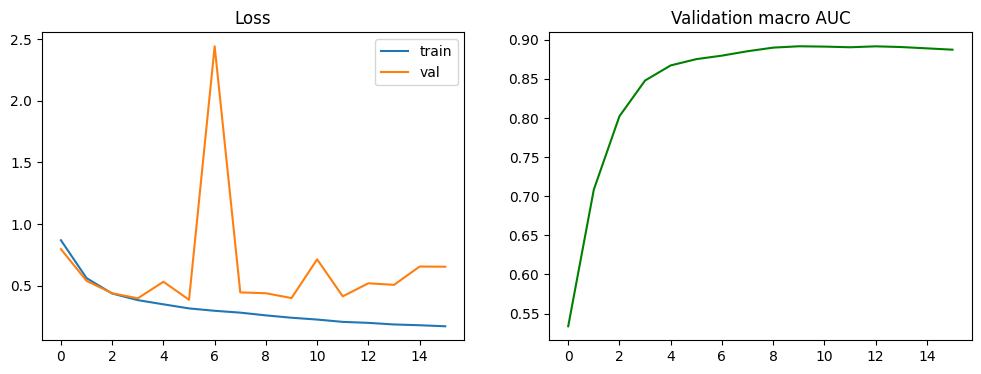

[seed 2024] best val macro AUC: 0.8918


In [9]:
OUT_DIR = "/kaggle/working"
SEEDS = [42, 123, 2024]      # one model per seed; use 2 seeds to train faster
EPOCHS = 20
RETRAIN = False              # True = ignore saved models and train everything again

def find_file(name):
    """Look for a saved file in /kaggle/working first, then in any attached input."""
    p = os.path.join(OUT_DIR, name)
    if os.path.exists(p):
        return p
    for r, _, files in os.walk(INPUT_ROOT):
        if name in files:
            return os.path.join(r, name)
    return None

def build_model(pretrained):
    return timm.create_model('efficientnet_b3', pretrained=pretrained, num_classes=NUM_CLASSES,
                             drop_rate=0.4, drop_path_rate=0.3).to(device)

def train_one_model(seed):
    name = f"b3_seed{seed}.pth"
    if not RETRAIN and find_file(name):
        print(f"[seed {seed}] found {name} -> skipping training")
        return
    print(f"\n===== Training model with seed {seed} =====")
    seed_everything(seed)
    model = build_model(pretrained=True)
    ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(0.997), use_buffers=True)
    criterion = nn.BCEWithLogitsLoss(pos_weight=make_pos_weight())

    head_params = list(model.get_classifier().parameters())
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    optimizer = torch.optim.AdamW([
        {'params': backbone_params, 'lr': 1e-4},
        {'params': head_params,     'lr': 1e-3},
    ], weight_decay=1e-2)
    warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=1)
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS - 1)
    scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, [warmup, cosine], milestones=[1])
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    _, best = fit(model, make_train_loader(seed), val_loader, criterion, optimizer, scheduler,
                  scaler, epochs=EPOCHS, patience=6,
                  save_path=os.path.join(OUT_DIR, name), ema=ema)
    print(f"[seed {seed}] best val macro AUC: {best:.4f}")
    del model, ema, optimizer
    torch.cuda.empty_cache()

for sd in SEEDS:
    train_one_model(sd)

In [10]:
CONFIG_NAME = "ensemble_config.json"
FORCE_RECALC_THRESHOLDS = False   # True = recompute thresholds from validation

def load_models():
    models = []
    for sd in SEEDS:
        path = find_file(f"b3_seed{sd}.pth")
        assert path is not None, f"Missing checkpoint for seed {sd}"
        m = build_model(pretrained=False)
        m.load_state_dict(torch.load(path, map_location=device))
        m.eval()
        models.append(m)
    return models

models = load_models()
print("Loaded", len(models), "models")

@torch.no_grad()
def ens_predict(x):
    """Average TTA probabilities across all ensemble members."""
    return torch.stack([predict_tta(m, x) for m in models]).mean(0)

@torch.no_grad()
def evaluate_ens(loader):
    probs_all, labels_all = [], []
    for imgs, labels in tqdm(loader, leave=False, desc="ensemble eval"):
        probs_all.append(ens_predict(imgs.to(device, non_blocking=True)).cpu().numpy())
        labels_all.append(labels.numpy())
    return np.concatenate(probs_all), np.concatenate(labels_all)

val_probs, val_labels = evaluate_ens(val_loader)
test_probs, test_labels = evaluate_ens(test_loader)

# Thresholds: load the saved ones (consistent numbers) or compute from VALIDATION and save
cfg_path = find_file(CONFIG_NAME)
if cfg_path and not FORCE_RECALC_THRESHOLDS:
    THRESHOLDS = json.load(open(cfg_path))['thresholds']
    print("Loaded saved thresholds from", cfg_path)
else:
    THRESHOLDS = find_best_thresholds(val_labels, val_probs)
    json.dump({'thresholds': THRESHOLDS, 'seeds': SEEDS},
              open(os.path.join(OUT_DIR, CONFIG_NAME), 'w'), indent=2)
    print("Computed and saved thresholds ->", os.path.join(OUT_DIR, CONFIG_NAME))
print("Thresholds:", THRESHOLDS)

# Final numbers on TEST
aucs = per_class_auc(test_labels, test_probs)
preds = np.stack([(test_probs[:, i] >= THRESHOLDS[c]).astype(int)
                  for i, c in enumerate(CLASSES)], axis=1)

print("\nTest AUC per class:")
for c in CLASSES:
    print(f"  {c} ({CLASS_NAMES[c]}): {aucs[c]:.4f}")
print(f"\nMacro AUC            : {np.nanmean(list(aucs.values())):.4f}")
print(f"Mean per-label acc.  : {(preds == test_labels).mean():.4f}")
print(f"Exact-match accuracy : {(preds == test_labels).all(axis=1).mean():.4f}")
print(f"Macro F1             : {f1_score(test_labels, preds, average='macro', zero_division=0):.4f}")
print("\n", classification_report(test_labels, preds, target_names=CLASSES, zero_division=0))

Loaded 3 models


ensemble eval:   0%|          | 0/60 [00:00<?, ?it/s]

ensemble eval:   0%|          | 0/60 [00:00<?, ?it/s]

Computed and saved thresholds -> /kaggle/working/ensemble_config.json
Thresholds: {'N': 0.475, 'D': 0.575, 'G': 0.375, 'C': 0.85, 'A': 0.3, 'H': 0.15, 'M': 0.8, 'O': 0.35}

Test AUC per class:
  N (Normal): 0.8687
  D (Diabetic Retinopathy): 0.8817
  G (Glaucoma): 0.9500
  C (Cataract): 0.9756
  A (AMD): 0.9477
  H (Hypertensive Retinopathy): 0.9381
  M (Pathological Myopia): 0.9978
  O (Other abnormalities): 0.8530

Macro AUC            : 0.9266
Mean per-label acc.  : 0.9159
Exact-match accuracy : 0.5750
Macro F1             : 0.6518

               precision    recall  f1-score   support

           N       0.73      0.86      0.79       437
           D       0.80      0.62      0.70       260
           G       0.48      0.73      0.58        49
           C       0.84      0.81      0.83        53
           A       0.58      0.83      0.68        58
           H       0.16      0.71      0.27        21
           M       0.93      0.90      0.92        30
           O       0.38 

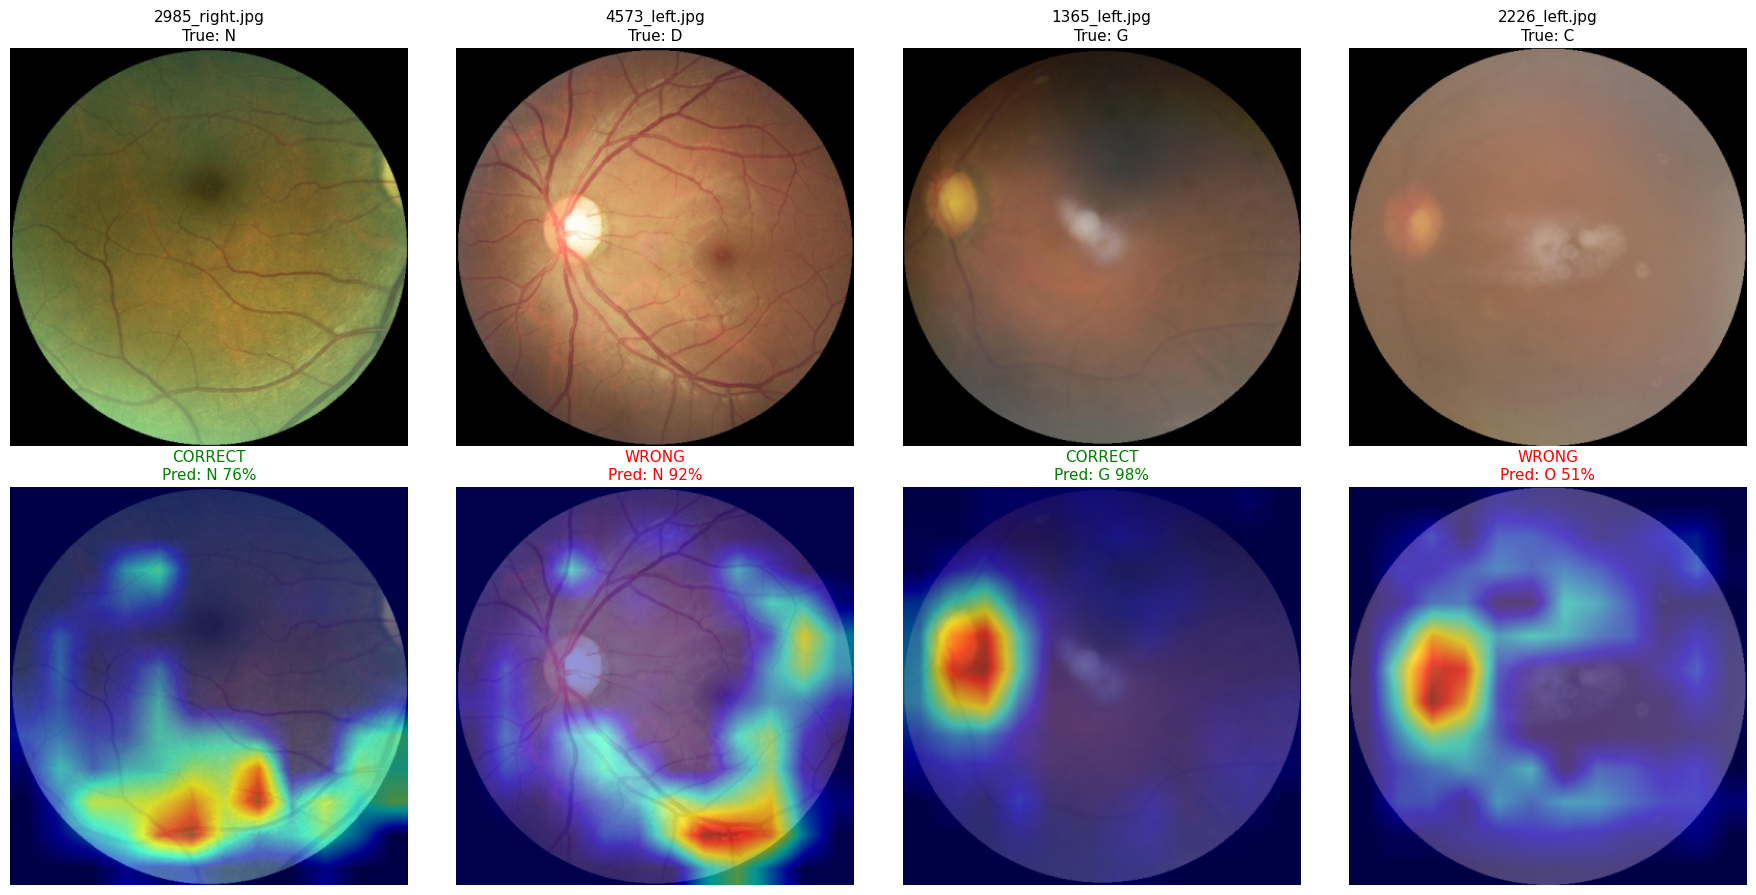

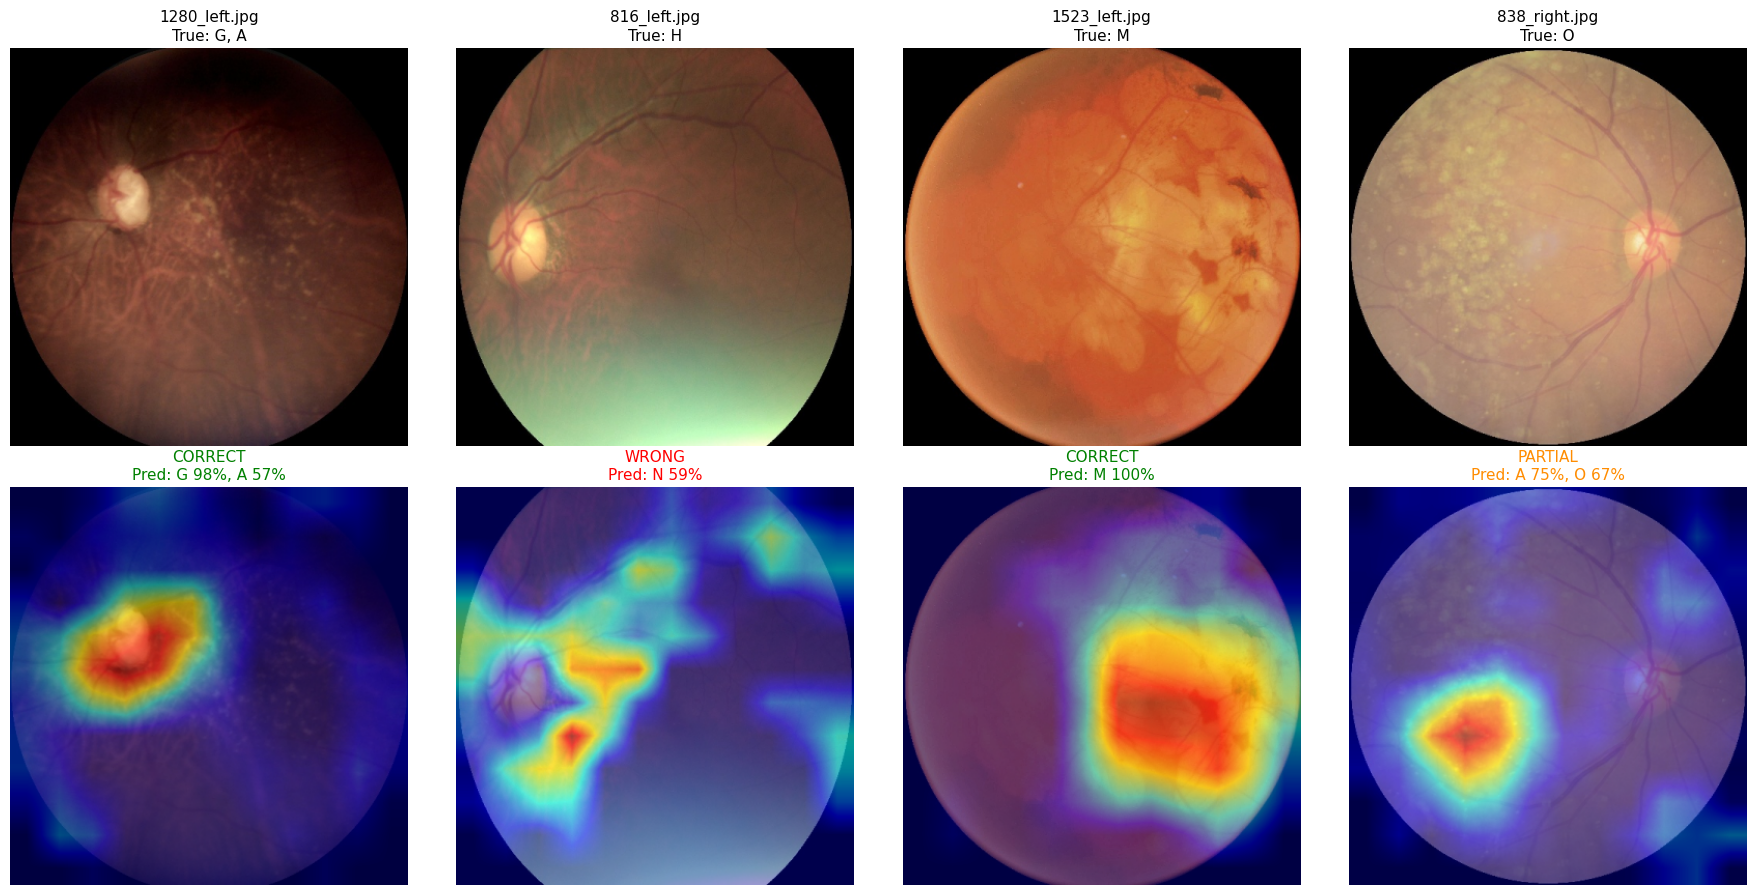

,filename,true,pred,verdict
0,2985_right.jpg,[N],[N],CORRECT
1,4573_left.jpg,[D],[N],WRONG
2,1365_left.jpg,[G],[G],CORRECT
3,2226_left.jpg,[C],[O],WRONG
4,1280_left.jpg,"[G, A]","[G, A]",CORRECT
5,816_left.jpg,[H],[N],WRONG
6,1523_left.jpg,[M],[M],CORRECT
7,838_right.jpg,[O],"[A, O]",PARTIAL


In [11]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

cam = GradCAM(model=models[0], target_layers=[models[0].blocks[-1]])

def get_cam(rgb, x, class_idx):
    g = cam(input_tensor=x, targets=[ClassifierOutputTarget(class_idx)])[0]
    return show_cam_on_image(rgb.astype(np.float32) / 255.0, g, use_rgb=True)

def predict_probs(rgb):
    x = to_tensor(rgb).to(device)
    p = ens_predict(x)[0].cpu().numpy()
    return p, x

def show_examples(df, per_class=1, seed=0, cols=4):
    """Test examples per disease: filename, true labels, predictions, heatmap."""
    parts = []
    for c in CLASSES:
        sub = df[df[c] == 1]
        if len(sub):
            parts.append(sub.sample(min(per_class, len(sub)), random_state=seed))
    samples = pd.concat(parts).drop_duplicates('filename').reset_index(drop=True)

    records = []
    for start in range(0, len(samples), cols):
        chunk = samples.iloc[start:start + cols]
        fig, axes = plt.subplots(2, cols, figsize=(4.5 * cols, 9))
        axes = np.atleast_2d(axes)
        for j in range(cols):
            axes[0, j].axis('off'); axes[1, j].axis('off')
        for j, (_, s) in enumerate(chunk.iterrows()):
            rgb = load_rgb(s['path'])
            probs, x = predict_probs(rgb)
            true = [c for c in CLASSES if s[c] == 1]
            pred = [c for i, c in enumerate(CLASSES) if probs[i] >= THRESHOLDS[c]]
            top = int(np.argmax(probs))
            pred_txt = ", ".join(f"{c} {probs[CLASSES.index(c)]*100:.0f}%" for c in pred) or \
                       f"none (top: {CLASSES[top]} {probs[top]*100:.0f}%)"
            if set(pred) == set(true):  color, verdict = "green", "CORRECT"
            elif set(pred) & set(true): color, verdict = "darkorange", "PARTIAL"
            else:                       color, verdict = "red", "WRONG"

            axes[0, j].imshow(rgb)
            axes[0, j].set_title(f"{s['filename']}\nTrue: {', '.join(true)}", fontsize=11)
            axes[1, j].imshow(get_cam(rgb, x, top))
            axes[1, j].set_title(f"{verdict}\nPred: {pred_txt}", fontsize=11, color=color)
            records.append({'filename': s['filename'], 'true': true, 'pred': pred, 'verdict': verdict})
        plt.tight_layout()
        plt.show()
    return pd.DataFrame(records)

examples = show_examples(test_df, per_class=1, seed=0)
examples

In [12]:
def analyze_rgb(rgb_in, crop=True, top_k=3, min_prob=0.15):
    """Stage 1 analysis of any RGB numpy image (can come from outside the dataset)."""
    rgb = prepare_rgb(rgb_in, crop=crop)
    probs, x = predict_probs(rgb)

    detected = [c for i, c in enumerate(CLASSES) if probs[i] >= THRESHOLDS[c]]
    if detected:
        status, shown = "DETECTED", detected
    else:
        status = "SUSPECTED (below threshold)"
        order = np.argsort(-probs)[:top_k]
        shown = [CLASSES[i] for i in order if probs[i] >= min_prob]

    top_idx = int(np.argmax(probs))
    return {'probs': probs, 'detected': detected, 'shown': shown, 'status': status,
            'heatmap': get_cam(rgb, x, top_idx), 'top': CLASSES[top_idx],
            'trigger_stage2': 'D' in detected}

# Consistency check: the same image must give exactly the same numbers every time
_img = cv2.cvtColor(cv2.imread(test_df.iloc[0]['path']), cv2.COLOR_BGR2RGB)
r1, r2 = analyze_rgb(_img), analyze_rgb(_img)
print("Same input -> same output:", np.allclose(r1['probs'], r2['probs']))

Same input -> same output: True


In [13]:
!pip install gradio -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [14]:
import gradio as gr

def gradio_predict(img):
    if img is None:
        return None, {}, "Please upload a fundus image."
    r = analyze_rgb(img, crop=True)
    label_dict = {f"{CLASS_NAMES[c]} ({c})": float(r['probs'][i]) for i, c in enumerate(CLASSES)}
    lines = [f"**Status:** {r['status']}"]
    for c in r['shown']:
        lines.append(f"- {CLASS_NAMES[c]}: **{r['probs'][CLASSES.index(c)]*100:.1f}%**")
    if not r['shown']:
        lines.append("- No disease above the minimum probability.")
    lines.append(f"\n**Trigger Stage 2 (Diabetic Retinopathy analysis):** {r['trigger_stage2']}")
    lines.append("\n*Research prototype only, not a medical diagnosis.*")
    return r['heatmap'], label_dict, "\n".join(lines)

demo = gr.Interface(
    fn=gradio_predict,
    inputs=gr.Image(type="numpy", label="Upload a fundus image"),
    outputs=[gr.Image(label="Grad-CAM (where the model looked)"),
             gr.Label(num_top_classes=8, label="Probabilities"),
             gr.Markdown(label="Report")],
    title="Eye Disease Classifier - Stage 1 (EfficientNet-B3 Ensemble)",
    description="Upload a retinal fundus photo to get disease probabilities and a Grad-CAM heatmap.",
)
demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://5dfe00264b78911724.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
